# 02 (real data) -- Forecast Evaluation on Real FR Data (2019-2026)

**This notebook uses REAL FR market data** fetched via `fr-power fetch`
(ENTSO-E Transparency Platform, 2019-01-01 to 2026-08-22, ~66,950 hourly
rows) -- not the synthetic generator used in `02_forecast_eval.ipynb`.

It loads the *already-computed* walk-forward predictions from
`data/processed/forecast_predictions.parquet` (produced by `fr-power train`,
which took ~2h15 for the full 69-fold walk-forward across all 4 models) --
**it does not retrain anything**, except a single, fast (~10s) full-sample
LightGBM fit at the end purely for feature-importance inspection.

See [`../reports/conclusions.md`](../reports/conclusions.md) ("Real FR
day-ahead price forecasting results") for the same numbers in context, and
for why the target here is the day-ahead price *level* rather than the
intraday-vs-day-ahead spread (no granular intraday feed is configured).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from fr_power.models.metrics import diebold_mariano_test, evaluate_predictions

plt.rcParams["figure.figsize"] = (10, 4)

matrix = pd.read_parquet("../data/processed/feature_matrix.parquet")
predictions = pd.read_parquet("../data/processed/forecast_predictions.parquet")

target_col = "target_day_ahead_price_eur_mwh"
actual = matrix[target_col]

print(f"{len(matrix):,} hourly rows, {matrix.index.min()} to {matrix.index.max()}")
print("out-of-sample coverage per model:")
print(predictions.notna().sum())

66,953 hourly rows, 2019-01-01 00:00:00+01:00 to 2026-08-22 00:00:00+02:00
out-of-sample coverage per model:
naive       49433
lear        49385
lightgbm    49433
lstm        36272
dtype: int64


## Evaluation metrics (RMSE / MAE / MdAE)

In [2]:
metrics_df = pd.DataFrame(
    {name: evaluate_predictions(actual, predictions[name]) for name in predictions.columns}
).T
metrics_df

,rmse,mae,mdae
naive,61.729872,37.686560,23.140000
lear,33.408017,18.908950,12.522778
lightgbm,56.951982,29.144615,14.114459
lstm,56.729704,32.425429,19.055550


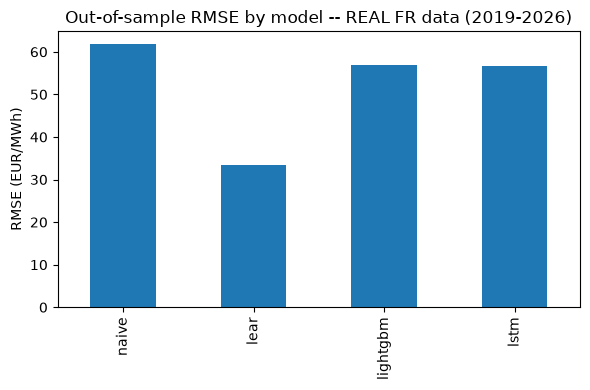

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
metrics_df["rmse"].plot.bar(ax=ax)
ax.set_ylabel("RMSE (EUR/MWh)")
ax.set_title("Out-of-sample RMSE by model -- REAL FR data (2019-2026)")
plt.tight_layout()
plt.show()

## Diebold-Mariano tests

A significantly negative `dm_stat` (p < 0.05) means the *challenger* has lower average loss than the *baseline*; positive means the challenger is *worse*.

In [4]:
comparisons = [
    ("lear", "naive"), ("lightgbm", "naive"), ("lightgbm", "lear"),
    ("lstm", "naive"), ("lstm", "lear"),
]
rows = []
for challenger, baseline in comparisons:
    aligned = pd.concat(
        [(actual - predictions[challenger]).rename("c"), (actual - predictions[baseline]).rename("b")],
        axis=1,
    ).dropna()
    stat, p = diebold_mariano_test(aligned["c"], aligned["b"])
    rows.append({"challenger": challenger, "baseline": baseline, "dm_stat": stat, "p_value": p})
dm_df = pd.DataFrame(rows)
dm_df

,challenger,baseline,dm_stat,p_value
0,lear,naive,-14.265132,0.000000
1,lightgbm,naive,-2.867289,0.004140
2,lightgbm,lear,38.257818,0.000000
3,lstm,naive,-2.396758,0.016541
4,lstm,lear,31.139584,0.000000


**LEAR wins decisively here**: both LightGBM and LSTM show a large *positive* `dm_stat` against LEAR (p < 0.001), i.e. significantly *worse*, not just statistically indistinguishable. See `reports/conclusions.md` for discussion of why.

## Visual comparison: actual vs. predicted (a sample period)

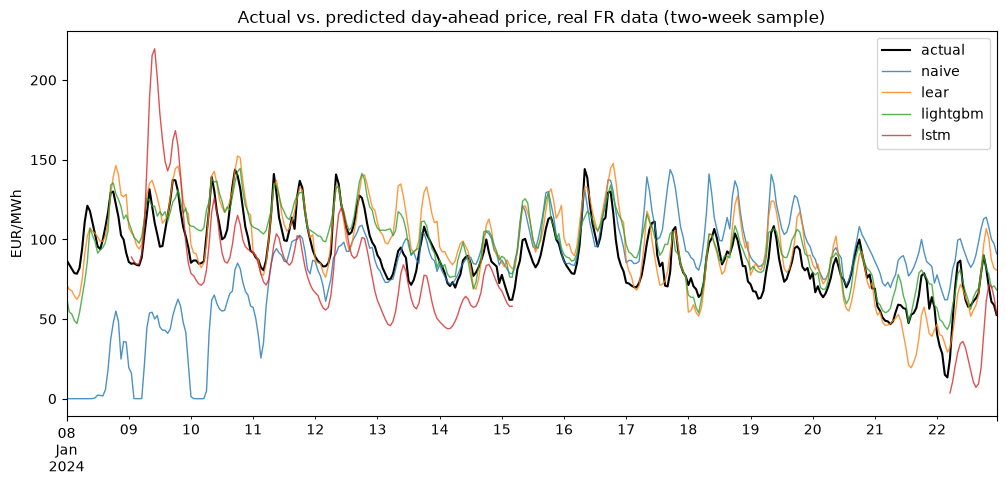

In [5]:
window = predictions.join(actual).loc["2024-01-08":"2024-01-22"]

fig, ax = plt.subplots(figsize=(12, 5))
window[target_col].plot(ax=ax, label="actual", color="black", linewidth=1.5)
for name in ["naive", "lear", "lightgbm", "lstm"]:
    window[name].plot(ax=ax, label=name, alpha=0.8, linewidth=1)
ax.set_ylabel("EUR/MWh")
ax.set_title("Actual vs. predicted day-ahead price, real FR data (two-week sample)")
ax.legend()
plt.show()

## Feature importance (LightGBM, single full-sample fit)

Not walk-forward -- one fast fit on the whole real dataset, purely to inspect which features the model leans on most. Matches the table already reported in `reports/conclusions.md`.

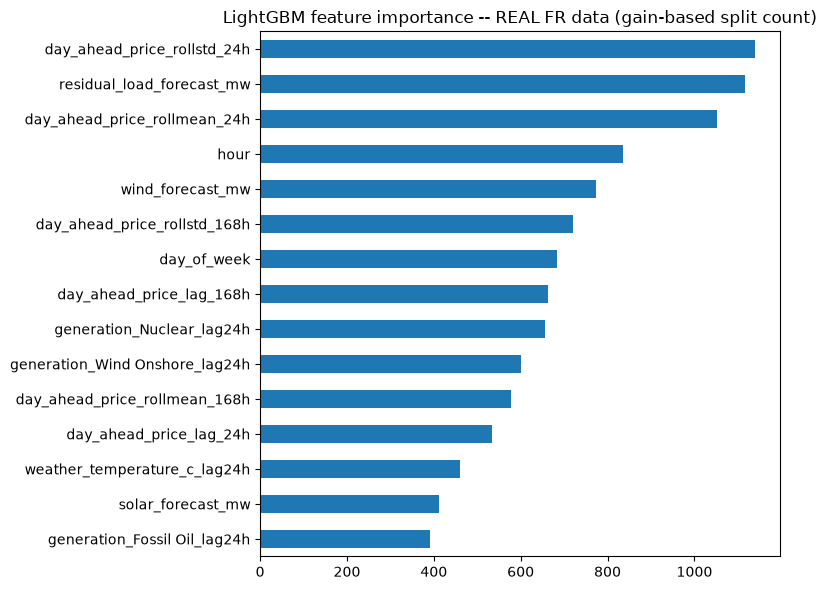

In [6]:
from fr_power.config import DEFAULT_CONFIG_PATH, load_config
from fr_power.models.gbm import LightGBMForecaster

cfg = load_config(DEFAULT_CONFIG_PATH)
feature_cols = [c for c in matrix.columns if not c.startswith("target_")]

final_model = LightGBMForecaster(**cfg.models.lightgbm.model_dump(), random_seed=cfg.project.random_seed)
final_model.fit(matrix[feature_cols], matrix[target_col])
importances = pd.Series(
    final_model.model_.feature_importances_, index=feature_cols
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
importances.head(15).sort_values().plot.barh(ax=ax)
ax.set_title("LightGBM feature importance -- REAL FR data (gain-based split count)")
plt.tight_layout()
plt.show()

---

See [`../reports/conclusions.md`](../reports/conclusions.md) for the full write-up: the French-vs-Danish market discussion, the regime-split methodology, and the complete list of data/modelling limitations (including why `calibrate`/`backtest` still can't run on this real data).